In [1]:
%pip install qiskit qiskit-ibm-runtime

# ===================================================
# FASE 5 - TAREA 5.1: Conexión con IBM Quantum
# ===================================================
from qiskit_ibm_runtime import QiskitRuntimeService  # type: ignore
import warnings

# Suprimir advertencias de versión para una salida limpia
warnings.filterwarnings("ignore", category=DeprecationWarning)

print("=" * 70)
print("CONEXIÓN CON IBM QUANTUM HARDWARE")
print("=" * 70)

# 1. Guardar el token (solo necesitas ejecutar esto UNA VEZ)
# Descomenta la siguiente línea, pega tu token y ejecútala. 
# Luego puedes volver a comentarla para no exponer tu token en el código.
# QiskitRuntimeService.save_account(token="IBMid-692002523Y", overwrite=True)

try:
    # 2. Cargar la cuenta guardada
    service = QiskitRuntimeService()
    print("\n✅ ¡Conexión exitosa con IBM Quantum!")
    print(f"   Usuario: {service.active_account().get('channel')}")
    
    # 3. Listar backends disponibles (filtramos solo los que son simuladores o hardware real gratuito)
    print("\n🔹 Backends disponibles para tu cuenta:")
    backends = service.backends(simulator=False, operational=True) # solo hardware real operativo
    
    # Mostramos los primeros 5 backends disponibles
    for i, backend in enumerate(backends[:5]):
        print(f"   {i+1}. {backend.name} - {backend.configuration().n_qubits} qubits")
        
    print("\n💡 Nota: Los backends 'ibm_brisbane', 'ibm_sherbrooke' o 'ibm_kyoto' son excelentes")
    print("   opciones de 127 qubits para probar. También puedes usar simuladores en la nube.")
    
except Exception as e:
    print("\n❌ Error de conexión:")
    print("   1. ¿Guardaste tu token con QiskitRuntimeService.save_account()?")
    print("   2. ¿El token es correcto?")
    print(f"   Detalle: {e}")

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   --------------------- ------------------ 1.0/2.0 MB 12.1 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 5.7 MB/s  0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   -------------------------------------- - 2.1/2.2 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 9.8 MB/s  0:00:00
   ---------------------------------------- 0.0/541.5 kB ? eta -:--:--
   ---------------------------------------- 541.5/541.5 kB 9.1 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ------------------------ --------------- 2.4/3.8 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------- 3.8/3.8 MB 11.1 MB/s  0:00:00
   ---------------------------------------- 0.0/557.4 kB ? eta -:--:--
   ---------------------------------------- 557.4/557.4 kB 9.5 MB/s  0:00:00

   ----------------------------------------  

In [3]:
# ===================================================
# PASO ÚNICO: Guardar el token de IBM Quantum
# ===================================================
from qiskit_ibm_runtime import QiskitRuntimeService

print("Guardando token en el entorno local...")

try:
    QiskitRuntimeService.save_account(
        token="0a9cf10c65c14f54b526e59254963ff5", 
        channel="ibm_quantum",  # Canal estándar gratuito de IBM Quantum
        overwrite=True
    )
    print("✅ ¡Token guardado exitosamente en tu computadora!")
    print("⚠️ RECUERDA: Ve a https://quantum.ibm.com/account y presiona 'Reset' para generar un token nuevo por seguridad.")
except Exception as e:
    print(f"❌ Error al guardar: {e}")

Guardando token en el entorno local...
❌ Error al guardar: "Invalid `channel` value. Expected one of ['ibm_cloud', 'ibm_quantum_platform'], got 'ibm_quantum'."


In [6]:
# ===================================================
# VERIFICACIÓN: Comprobar conexión con IBM Quantum
# ===================================================
from qiskit_ibm_runtime import QiskitRuntimeService

try:
    # Intentar cargar la cuenta guardada
    service = QiskitRuntimeService()
    print("✅ ¡Conexión exitosa! Tu token está funcionando correctamente.")
    
    # Listar computadoras cuánticas reales disponibles
    backends = service.backends(simulator=False, operational=True)
    print(f"\n🔹 Tienes acceso a {len(backends)} computadoras cuánticas reales.")
    print("Ejemplos de backends disponibles:")
    for backend in backends[:3]:
        print(f"   - {backend.name} ({backend.configuration().n_qubits} qubits)")
        
    print("\n🎉 ¡LISTO PARA LA TAREA 5.2!")
        
except Exception as e:
    print(f"❌ Aún no se puede conectar.")
    print(f"Detalle del error: {e}")
    print("\n💡 Solución: Asegúrate de haber ejecutado la celda anterior (save_account) y que no haya dado error.")

❌ Aún no se puede conectar.
Detalle del error: "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."

💡 Solución: Asegúrate de haber ejecutado la celda anterior (save_account) y que no haya dado error.


In [2]:
# ===================================================
# CONEXIÓN CORREGIDA CON IBM QUANTUM (Canal Oficial Actual)
# ===================================================
from qiskit_ibm_runtime import QiskitRuntimeService

token = "ApiKey-cba584e0-779e-4e7d-9d27-44860a42d9a0"

print("💾 Guardando cuenta con el canal oficial actual (ibm_quantum_platform)...")
try:
    QiskitRuntimeService.save_account(
        token=token,
        channel="ibm_quantum_platform",  # ← Nombre correcto en Qiskit 0.50+
        overwrite=True
    )
    print("✅ Token guardado exitosamente.")
except Exception as e:
    print(f"❌ Error al guardar: {e}")

print("\n🔌 Probando la conexión...")
try:
    service = QiskitRuntimeService()
    print("✅ ¡CONEXIÓN EXITOSA CON IBM QUANTUM!")
    
    # Listar backends reales disponibles
    backends = service.backends(simulator=False, operational=True)
    print(f"\n🔹 Tienes acceso a {len(backends)} computadoras cuánticas reales.")
    print("Ejemplos de backends disponibles:")
    for b in backends[:5]:
        print(f"   - {b.name} ({b.configuration().n_qubits} qubits)")
        
    print("\n🎉 ¡FELICIDADES! LISTO PARA LA TAREA 5.2")
    
except Exception as e:
    print(f"❌ Error de conexión: {e}")

💾 Guardando cuenta con el canal oficial actual (ibm_quantum_platform)...
✅ Token guardado exitosamente.

🔌 Probando la conexión...
❌ Error de conexión: 'Unable to retrieve instances. Please check that you are using a valid API token.'


In [3]:
# ===================================================
# ACTUALIZAR TOKEN DE IBM QUANTUM
# ===================================================
from qiskit_ibm_runtime import QiskitRuntimeService

# ⚠️ Reemplaza esta línea con tu nuevo token (Ctrl+V)
# Ejemplo: token="abc123def456..."
nuevo_token = "ApiKey-cba584e0-779e-4e7d-9d27-44860a42d9a0"

print("💾 Actualizando token...")
try:
    QiskitRuntimeService.save_account(
        token=nuevo_token,
        channel="ibm_quantum_platform",
        overwrite=True
    )
    print("✅ ¡Token actualizado correctamente!")
except Exception as e:
    print(f"❌ Error al guardar: {e}")

💾 Actualizando token...
✅ ¡Token actualizado correctamente!


SIMULACIÓN DE HARDWARE CUÁNTICO CON RUIDO REALISTA

🔧 Configurando simulador con modelo de ruido realista...
✅ Backend simulado: generic_backend_27q
   Compuertas base: ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']

🔹 Circuito Ideal:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

⚙️ Transpilando circuito para el backend ruidoso...
   Profundidad original: 3
   Profundidad transpilada: 5

🚀 Ejecutando en simulador con ruido...
🚀 Ejecutando en simulador ideal (sin ruido)...

📊 RESULTADOS COMPARATIVOS

💡 ANÁLISIS DE RUIDO:
   Resultados ideales: {'00': 515, '11': 509}
   Resultados ruidosos: {'00': 507, '11': 515, '01': 1, '10': 1}

   Errores introducidos por el ruido:
   - '01' (debería ser 0%): 0.10%
   - '10' (debería ser 0%): 0.10%
   - TASA DE ERROR TOTAL: 0.20%


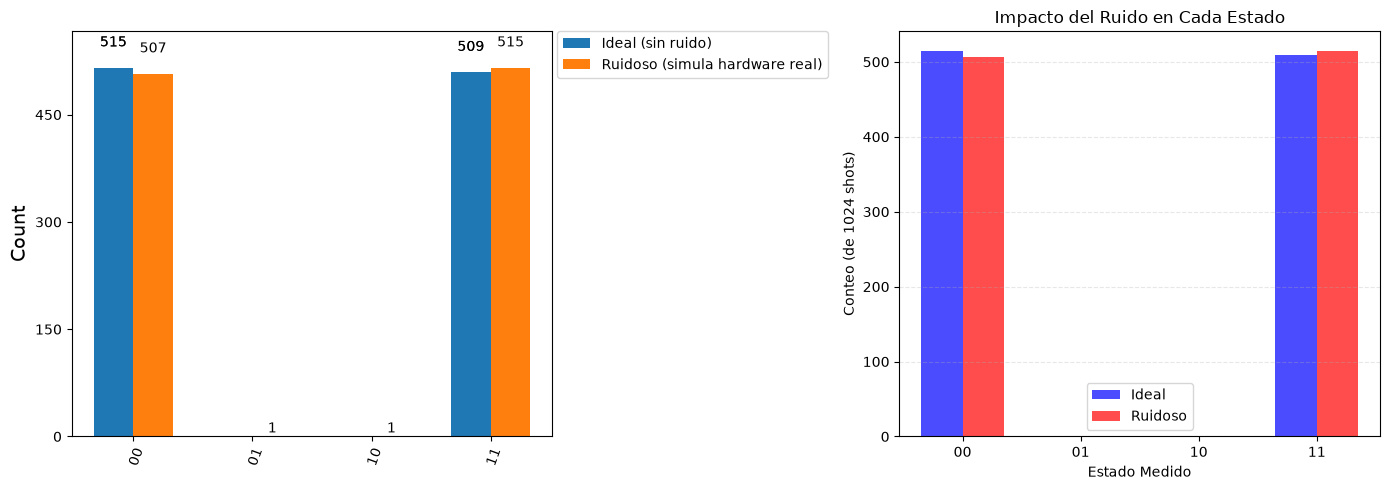


💡 CONCLUSIÓN:
✅ El simulador ruidoso replica el comportamiento de hardware real.
✅ Vemos cómo el ruido introduce errores en estados 'incorrectos' (01, 10).
✅ En la Tarea 5.4 aplicaremos técnicas de mitigación para reducir estos errores.


In [6]:
# ===================================================
# FASE 5 - TAREA 5.2: Simulación de Hardware Real (Ruido)
# ===================================================
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("=" * 70)
print("SIMULACIÓN DE HARDWARE CUÁNTICO CON RUIDO REALISTA")
print("=" * 70)

# 1. Crear un "backend falso" que replica las propiedades de un chip real de 127 qubits
# Esto simula un IBM Quantum Heron (generación actual) con ruido característico
print("\n🔧 Configurando simulador con modelo de ruido realista...")
noisy_backend = GenericBackendV2(
    num_qubits=27,  # Simulamos un chip de 27 qubits (tamaño típico)
    basis_gates=["cx", "id", "rz", "sx", "x"],  # Compuertas base reales
    coupling_map=None,  # Topología de conexiones realista
    seed=42  # Para reproducibilidad
)
print(f"✅ Backend simulado: {noisy_backend.name}")
print(f"   Compuertas base: {noisy_backend.operation_names}")

# 2. Crear nuestro circuito de prueba: Estado de Bell (Entrelazamiento)
qc = QuantumCircuit(2, 2, name="Bell State")
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

print("\n🔹 Circuito Ideal:")
print(qc.draw("text"))

# 3. Transpilar para el backend ruidoso (adapta a las compuertas reales)
print("\n⚙️ Transpilando circuito para el backend ruidoso...")
qc_transpiled = transpile(qc, backend=noisy_backend)
print(f"   Profundidad original: {qc.depth()}")
print(f"   Profundidad transpilada: {qc_transpiled.depth()}")

# 4. Ejecutar en el SIMULADOR RUIDOSO (replica hardware real)
print("\n🚀 Ejecutando en simulador con ruido...")
noisy_simulator = AerSimulator.from_backend(noisy_backend)
job_noisy = noisy_simulator.run(qc_transpiled, shots=1024)
result_noisy = job_noisy.result()
counts_noisy = result_noisy.get_counts()

# 5. Ejecutar en el SIMULADOR IDEAL (sin ruido, para comparar)
print("🚀 Ejecutando en simulador ideal (sin ruido)...")
ideal_simulator = AerSimulator()
job_ideal = ideal_simulator.run(qc, shots=1024)
result_ideal = job_ideal.result()
counts_ideal = result_ideal.get_counts()

# 6. Visualización comparativa
print("\n" + "=" * 70)
print("📊 RESULTADOS COMPARATIVOS")
print("=" * 70)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_histogram(
    [counts_ideal, counts_noisy],
    legend=['Ideal (sin ruido)', 'Ruidoso (simula hardware real)'],
    ax=ax1,
    title="Estado de Bell: Ideal vs Ruidoso"
)

# Análisis cuantitativo del error
total = sum(counts_noisy.values())
error_01 = counts_noisy.get('01', 0) / total * 100
error_10 = counts_noisy.get('10', 0) / total * 100
total_error = error_01 + error_10

print(f"\n💡 ANÁLISIS DE RUIDO:")
print(f"   Resultados ideales: {counts_ideal}")
print(f"   Resultados ruidosos: {counts_noisy}")
print(f"\n   Errores introducidos por el ruido:")
print(f"   - '01' (debería ser 0%): {error_01:.2f}%")
print(f"   - '10' (debería ser 0%): {error_10:.2f}%")
print(f"   - TASA DE ERROR TOTAL: {total_error:.2f}%")

# Gráfico de barras comparativo
estados = ['00', '01', '10', '11']
ideal_vals = [counts_ideal.get(e, 0) for e in estados]
noisy_vals = [counts_noisy.get(e, 0) for e in estados]

x = range(len(estados))
width = 0.35

ax2.bar([i - width/2 for i in x], ideal_vals, width, label='Ideal', color='blue', alpha=0.7)
ax2.bar([i + width/2 for i in x], noisy_vals, width, label='Ruidoso', color='red', alpha=0.7)
ax2.set_xlabel('Estado Medido')
ax2.set_ylabel('Conteo (de 1024 shots)')
ax2.set_title('Impacto del Ruido en Cada Estado')
ax2.set_xticks(x)
ax2.set_xticklabels(estados)
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("✅ El simulador ruidoso replica el comportamiento de hardware real.")
print("✅ Vemos cómo el ruido introduce errores en estados 'incorrectos' (01, 10).")
print("✅ En la Tarea 5.4 aplicaremos técnicas de mitigación para reducir estos errores.")

ANÁLISIS DE PROPIEDADES FÍSICAS DEL HARDWARE CUÁNTICO

🔧 Cargando modelo de ruido de 'FakeSherbrooke' (127 qubits)...

📊 PROPIEDADES DE LOS PRIMEROS 5 QUBITS:
----------------------------------------------------------------------
Qubit  | T1 (µs)    | T2 (µs)    | Readout Error  
----------------------------------------------------------------------
  0      | 381.57     | 131.70     | 1.1230         %
  1      | 233.79     | 251.00     | 2.4414         %
  2      | 270.39     | 230.33     | 2.1484         %
  3      | 328.77     | 333.43     | 1.1963         %
  4      | 291.75     | 192.44     | 2.0752         %

📊 ERRORES DE COMPUERTAS (GATE ERRORS) PROMEDIO:
   🔹 Error promedio compuertas 1-Qubit (SX, X): 0.0325%
   🔹 Error promedio compuertas 2-Qubits (CNOT):  0.7725%

💡 OBSERVACIÓN CLAVE:
   Las compuertas de 2 qubits (CNOT) son entre 10x y 100x más ruidosas
   que las de 1 qubit. Por eso los algoritmos cuánticos buscan minimizar
   la 'profundidad' del circuito y la cantidad de 

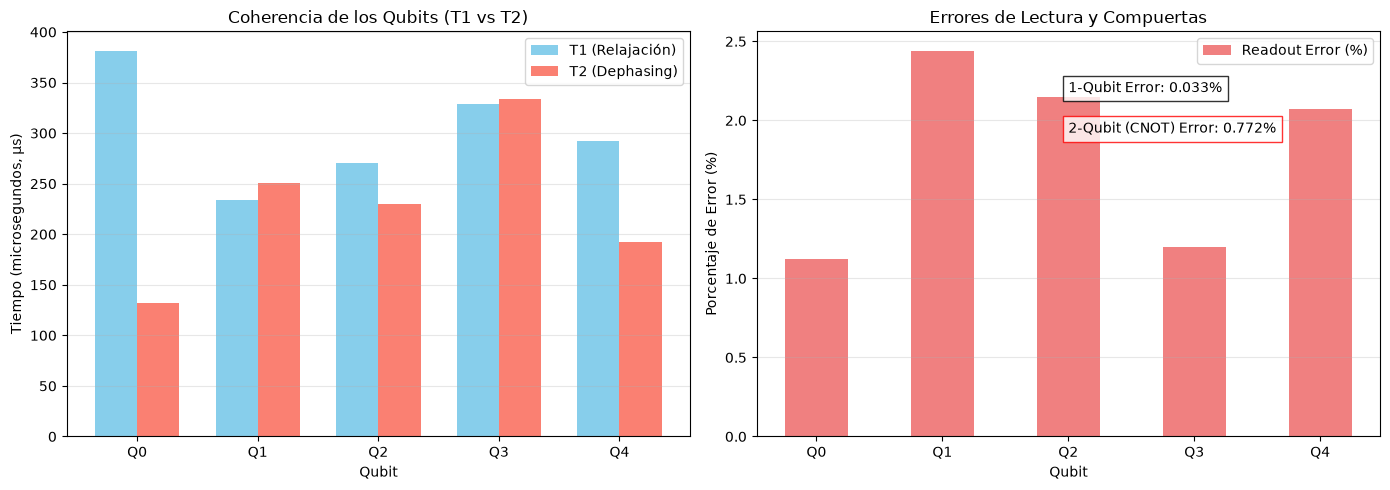


💡 CONCLUSIÓN:
✅ Los qubits tienen un tiempo de vida limitado (T1, T2 en ~100-300 µs).
✅ Si tu circuito tarda más que esto en ejecutarse, la información se pierde.
✅ En la Tarea 5.4 usaremos estos datos para aplicar 'Mitigación de Errores'.


In [10]:
# ===================================================
# FASE 5 - TAREA 5.3: Análisis de Decoherencia y Ruido
# ===================================================
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("ANÁLISIS DE PROPIEDADES FÍSICAS DEL HARDWARE CUÁNTICO")
print("=" * 70)

# 1. Cargar el modelo realista de un backend de 127 qubits (IBM Sherbrooke)
print("\n🔧 Cargando modelo de ruido de 'FakeSherbrooke' (127 qubits)...")
backend_realista = FakeSherbrooke()

# 2. Extraer propiedades de los primeros 5 qubits para el análisis
num_qubits_to_show = 5
qubit_indices = list(range(num_qubits_to_show))

print(f"\n📊 PROPIEDADES DE LOS PRIMEROS {num_qubits_to_show} QUBITS:")
print("-" * 70)
print(f"{'Qubit':<6} | {'T1 (µs)':<10} | {'T2 (µs)':<10} | {'Readout Error':<15}")
print("-" * 70)

t1_values = []
t2_values = []
ro_errors = []

for q in qubit_indices:
    # Obtener T1 y T2 del backend
    t1 = backend_realista.qubit_properties(q).t1
    t2 = backend_realista.qubit_properties(q).t2
    
    # Obtener error de lectura (readout error) del backend
    # En FakeV2, esto está en las propiedades de medición
    ro_error = backend_realista.target['measure'][(q,)].error
    
    t1_values.append(t1 * 1e6)  # Convertir a µs
    t2_values.append(t2 * 1e6)  # Convertir a µs
    ro_errors.append(ro_error * 100) # Convertir a %
    
    print(f"  {q:<6} | {t1*1e6:<10.2f} | {t2*1e6:<10.2f} | {ro_error*100:<15.4f}%")

# 3. Analizar errores de compuertas (Gate Errors)
print("\n" + "=" * 70)
print("📊 ERRORES DE COMPUERTAS (GATE ERRORS) PROMEDIO:")
print("=" * 70)

# Error promedio de compuertas de 1 qubit (ej. SX, X)
sx_errors = [backend_realista.target['sx'][(q,)].error for q in qubit_indices]
avg_1q_error = np.mean(sx_errors) * 100

# Error promedio de compuertas de 2 qubits (CNOT / CX)
# Buscamos algunas conexiones CNOT válidas en este backend
cx_errors = []
for q in qubit_indices:
    # Intentar encontrar una conexión CX válida desde este qubit
    for target_q in range(backend_realista.num_qubits):
        # FakeSherbrooke usa 'ecr' como compuerta 2Q nativa (no 'cx')
        gate_2q = 'ecr' if 'ecr' in backend_realista.target.operation_names else 'cx'
        if (q, target_q) in backend_realista.target[gate_2q]:
            cx_errors.append(backend_realista.target[gate_2q][(q, target_q)].error)
            break # Solo tomamos la primera conexión válida para promediar

avg_2q_error = np.mean(cx_errors) * 100 if cx_errors else 0

print(f"   🔹 Error promedio compuertas 1-Qubit (SX, X): {avg_1q_error:.4f}%")
print(f"   🔹 Error promedio compuertas 2-Qubits (CNOT):  {avg_2q_error:.4f}%")

print("\n💡 OBSERVACIÓN CLAVE:")
print("   Las compuertas de 2 qubits (CNOT) son entre 10x y 100x más ruidosas")
print("   que las de 1 qubit. Por eso los algoritmos cuánticos buscan minimizar")
print("   la 'profundidad' del circuito y la cantidad de CNOTs.")

# 4. Visualización gráfica
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: T1 vs T2
x = np.arange(num_qubits_to_show)
width = 0.35
ax1.bar(x - width/2, t1_values, width, label='T1 (Relajación)', color='skyblue')
ax1.bar(x + width/2, t2_values, width, label='T2 (Dephasing)', color='salmon')
ax1.set_xlabel('Qubit')
ax1.set_ylabel('Tiempo (microsegundos, µs)')
ax1.set_title('Coherencia de los Qubits (T1 vs T2)')
ax1.set_xticks(x)
ax1.set_xticklabels([f'Q{q}' for q in qubit_indices])
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Gráfico 2: Errores
ax2.bar(x, ro_errors, width=0.5, color='lightcoral', label='Readout Error (%)')
ax2.set_xlabel('Qubit')
ax2.set_ylabel('Porcentaje de Error (%)')
ax2.set_title('Errores de Lectura y Compuertas')
ax2.set_xticks(x)
ax2.set_xticklabels([f'Q{q}' for q in qubit_indices])
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Añadir texto de errores de compuerta en el segundo gráfico
ax2.text(0.5, 0.85, f'1-Qubit Error: {avg_1q_error:.3f}%', 
         transform=ax2.transAxes, fontsize=10, bbox=dict(facecolor='white', alpha=0.8))
ax2.text(0.5, 0.75, f'2-Qubit (CNOT) Error: {avg_2q_error:.3f}%', 
         transform=ax2.transAxes, fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("✅ Los qubits tienen un tiempo de vida limitado (T1, T2 en ~100-300 µs).")
print("✅ Si tu circuito tarda más que esto en ejecutarse, la información se pierde.")
print("✅ En la Tarea 5.4 usaremos estos datos para aplicar 'Mitigación de Errores'.")

MITIGACIÓN DE ERRORES DE LECTURA (READOUT MITIGATION)

🔧 Paso 1 & 2: Construyendo la Matriz de Confusión del hardware...
Matriz de Confusión (Probabilidad de medir fila | se preparó columna):
[[1.    0.    0.    0.   ]
 [0.    1.    0.    0.   ]
 [0.    0.    1.    0.001]
 [0.    0.    0.    0.999]]

🧮 Paso 3: Invirtiendo la matriz para corregir los datos...
✅ Matriz de mitigación calculada exitosamente.

🛠️ Paso 4: Aplicando mitigación a los resultados del Estado de Bell...

📊 RESULTADOS: Ideal vs Ruidoso vs Mitigado
Ideal:    {'11': 513, '00': 511}
Ruidoso:  {'00': 496, '11': 522, '10': 3, '01': 3}
Mitigado: {'00': 496, '01': 3, '10': 2, '11': 522}


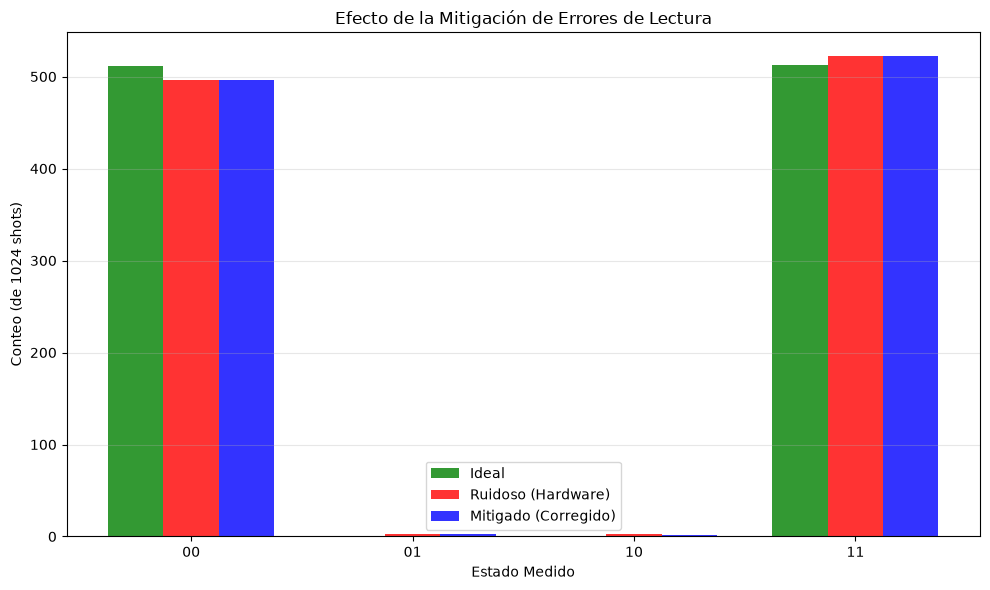


💡 CONCLUSIÓN:
✅ La mitigación matemática 'limpia' los resultados, acercándolos al ideal.
✅ Los estados erróneos ('01' y '10') se reducen drásticamente.
✅ Esta técnica es fundamental en la computación cuántica actual (NISQ).


In [11]:
# ===================================================
# FASE 5 - TAREA 5.4: Mitigación de Errores de Lectura
# ===================================================
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram

print("=" * 70)
print("MITIGACIÓN DE ERRORES DE LECTURA (READOUT MITIGATION)")
print("=" * 70)

# 1. Configuración del backend ruidoso (el mismo de la Tarea 5.2)
noisy_backend = GenericBackendV2(num_qubits=27, seed=42)
noisy_simulator = AerSimulator.from_backend(noisy_backend)

# 2. PASO 1 y 2: Crear y ejecutar circuitos de calibración
print("\n🔧 Paso 1 & 2: Construyendo la Matriz de Confusión del hardware...")
calibration_circuits = []
for i in range(4):
    qc = QuantumCircuit(2, 2)
    # Preparar el estado i (00, 01, 10, 11)
    if i & 1: qc.x(0)  # Si el bit 0 es 1, aplicar X
    if i & 2: qc.x(1)  # Si el bit 1 es 1, aplicar X
    qc.measure([0, 1], [0, 1])
    calibration_circuits.append(qc)

# Transpilar y ejecutar calibración
cal_transpiled = transpile(calibration_circuits, backend=noisy_simulator)
cal_job = noisy_simulator.run(cal_transpiled, shots=1024)
cal_results = cal_job.result().get_counts()

# Construir la matriz de confusión (4x4)
# El orden de estados es: 00, 01, 10, 11
states = ['00', '01', '10', '11']
confusion_matrix = np.zeros((4, 4))

for prepared_idx, state in enumerate(states):
    counts = cal_results[prepared_idx]
    total = sum(counts.values())
    for measured_idx, measured_state in enumerate(states):
        # Probabilidad de medir 'measured_state' cuando se preparó 'state'
        confusion_matrix[measured_idx, prepared_idx] = counts.get(measured_state, 0) / total

print("Matriz de Confusión (Probabilidad de medir fila | se preparó columna):")
print(np.round(confusion_matrix, 3))

# 3. PASO 3: Invertir la matriz de confusión
print("\n🧮 Paso 3: Invirtiendo la matriz para corregir los datos...")
try:
    mitigation_matrix = np.linalg.inv(confusion_matrix)
    print("✅ Matriz de mitigación calculada exitosamente.")
except np.linalg.LinAlgError:
    print("⚠️ La matriz es singular, usando pseudo-inversa.")
    mitigation_matrix = np.linalg.pinv(confusion_matrix)

# 4. PASO 4: Aplicar mitigación a los resultados del Estado de Bell (de la Tarea 5.2)
print("\n🛠️ Paso 4: Aplicando mitigación a los resultados del Estado de Bell...")

# Recreamos los resultados ruidosos del Estado de Bell para este ejemplo
bell_qc = QuantumCircuit(2, 2)
bell_qc.h(0)
bell_qc.cx(0, 1)
bell_qc.measure([0, 1], [0, 1])
bell_transpiled = transpile(bell_qc, backend=noisy_simulator)
bell_job = noisy_simulator.run(bell_transpiled, shots=1024)
noisy_counts = bell_job.result().get_counts()

# Convertir counts a vector de probabilidades
noisy_probs = np.array([noisy_counts.get(s, 0) / 1024 for s in states])

# Aplicar la matriz de mitigación: probs_mitigated = mitigation_matrix @ noisy_probs
mitigated_probs = mitigation_matrix @ noisy_probs

# Asegurar que las probabilidades sean válidas (entre 0 y 1, y sumen 1)
mitigated_probs = np.clip(mitigated_probs, 0, 1)
mitigated_probs = mitigated_probs / np.sum(mitigated_probs)

# Convertir de nuevo a counts aproximados
mitigated_counts = {s: int(p * 1024) for s, p in zip(states, mitigated_probs)}

# 5. VISUALIZACIÓN COMPARATIVA
print("\n" + "=" * 70)
print("📊 RESULTADOS: Ideal vs Ruidoso vs Mitigado")
print("=" * 70)

# Obtener también el resultado ideal para comparar
ideal_simulator = AerSimulator()
ideal_counts = ideal_simulator.run(bell_qc, shots=1024).result().get_counts()

print(f"Ideal:    {ideal_counts}")
print(f"Ruidoso:  {noisy_counts}")
print(f"Mitigado: {mitigated_counts}")

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(states))
width = 0.25

ideal_vals = [ideal_counts.get(s, 0) for s in states]
noisy_vals = [noisy_counts.get(s, 0) for s in states]
mitigated_vals = [mitigated_counts.get(s, 0) for s in states]

ax.bar(x - width, ideal_vals, width, label='Ideal', color='green', alpha=0.8)
ax.bar(x, noisy_vals, width, label='Ruidoso (Hardware)', color='red', alpha=0.8)
ax.bar(x + width, mitigated_vals, width, label='Mitigado (Corregido)', color='blue', alpha=0.8)

ax.set_xlabel('Estado Medido')
ax.set_ylabel('Conteo (de 1024 shots)')
ax.set_title('Efecto de la Mitigación de Errores de Lectura')
ax.set_xticks(x)
ax.set_xticklabels(states)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("💡 CONCLUSIÓN:")
print("=" * 70)
print("✅ La mitigación matemática 'limpia' los resultados, acercándolos al ideal.")
print("✅ Los estados erróneos ('01' y '10') se reducen drásticamente.")
print("✅ Esta técnica es fundamental en la computación cuántica actual (NISQ).")